# WaterLine — previsão de chuva forte nas próximas horas

**FIAP · Global Solution 2026.2 · IA & Machine Learning**

O WaterLine monitora bocas de lobo com sensores que mostram a situação atual de cada uma. Este notebook prevê se vai chover forte nas próximas horas, para que a limpeza das bocas de lobo seja feita antes da chuva.

O modelo usa as medições da estação meteorológica até o momento da previsão e indica se a chuva acumulada nas próximas 3 horas, e nas próximas 6 horas, vai chegar a 10 mm ou mais. É uma classificação binária: 1 indica chuva forte e 0 indica ausência de chuva forte. A previsão é enviada ao endpoint `POST /previsoes` da API WaterLine.

Etapas do notebook:
1. Carregamento dos dados reais do INMET e análise da qualidade
2. Definição do alvo e dos atributos
3. Divisão em treino e teste
4. Escolha do modelo
5. Treino com diferentes hiperparâmetros
6. Resultados no treino e no teste
7. Comparação entre os horizontes de 3 h e 6 h e com outros modelos
8. Interpretação dos resultados para o cidadão
9. Visualização do que a rede aprendeu
10. Modelo salvo para a API

In [1]:
import glob
import itertools
import json
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

SEMENTE = 42
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo:', device)

os.makedirs('figuras', exist_ok=True)
os.makedirs('modelo', exist_ok=True)

# Aparência dos gráficos: azul = treino, laranja = teste, em todas as figuras.
COR_TREINO, COR_TESTE, COR_NEUTRA = '#2a78d6', '#eb6834', '#898781'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'text.color': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'legend.frameon': False, 'figure.dpi': 110, 'lines.linewidth': 2,
})


def salvar(nome):
    plt.tight_layout()
    plt.savefig(f'figuras/{nome}.png', dpi=150, bbox_inches='tight')
    plt.show()

Dispositivo: cpu


## 1. Dados reais do INMET

Os dados são as medições horárias da estação automática A701 (São Paulo, Mirante de Santana), do Instituto Nacional de Meteorologia (INMET), baixadas do portal de dados históricos (https://portal.inmet.gov.br/dadoshistoricos). São quatro arquivos anuais, de 01/01/2023 a 31/10/2026. Nenhum valor foi simulado. A descrição das colunas está em `dados/README.md`.

Os arquivos do INMET têm 8 linhas de cabeçalho antes da tabela, colunas separadas por `;` e números com vírgula decimal. A função abaixo lê os quatro arquivos, junta tudo em uma única tabela com uma linha por hora e renomeia as colunas com nomes curtos.

In [2]:
COLUNAS = ['chuva', 'pressao', 'pressao_max', 'pressao_min', 'radiacao', 'temp', 'orvalho',
           'temp_max', 'temp_min', 'orvalho_max', 'orvalho_min', 'umid_max', 'umid_min',
           'umidade', 'vento_dir', 'vento_rajada', 'vento_vel']


def carregar_inmet(pasta):
    partes = []
    for caminho in sorted(glob.glob(os.path.join(pasta, '*.CSV'))):
        parte = pd.read_csv(caminho, sep=';', decimal=',', skiprows=8, encoding='latin1')
        parte = parte.loc[:, ~parte.columns.str.startswith('Unnamed')]
        partes.append(parte)
    bruto = pd.concat(partes, ignore_index=True)

    # Data ("2023/01/01") + hora ("0000 UTC") viram o índice de tempo, em UTC.
    momento = pd.to_datetime(bruto.iloc[:, 0] + ' ' + bruto.iloc[:, 1].str.slice(0, 4),
                             format='%Y/%m/%d %H%M')
    dados = bruto.iloc[:, 2:].apply(pd.to_numeric, errors='coerce')
    dados.columns = COLUNAS
    dados.index = momento
    dados.index.name = 'momento_utc'

    # O INMET usa -9999 (ou vazio) para "sem medição".
    dados = dados.replace(-9999, np.nan)

    # Garante uma linha por hora, sem buracos: as defasagens (shift) dependem disso.
    grade = pd.date_range(dados.index.min(), dados.index.max(), freq='h')
    return dados.reindex(grade)


df = carregar_inmet('dados/brutos')
print('Horas carregadas:', len(df), '| de', df.index.min(), 'a', df.index.max(), '(UTC)')
df.head()

Horas carregadas: 33600 | de 2023-01-01 00:00:00 a 2026-10-31 23:00:00 (UTC)


,chuva,pressao,pressao_max,pressao_min,radiacao,temp,orvalho,temp_max,temp_min,orvalho_max,orvalho_min,umid_max,umid_min,umidade,vento_dir,vento_rajada,vento_vel
2023-01-01 00:00:00,0.0,927.2,927.2,926.9,NaN,20.3,17.2,20.5,20.2,17.2,17.0,83.0,81.0,83.0,124.0,3.1,0.8
2023-01-01 01:00:00,0.0,927.2,927.2,926.9,NaN,20.2,17.5,20.4,20.1,17.6,17.2,85.0,82.0,84.0,143.0,3.1,1.0
2023-01-01 02:00:00,0.0,927.1,927.3,927.1,NaN,20.6,17.9,20.6,20.2,18.0,17.5,85.0,84.0,85.0,115.0,3.5,1.4
2023-01-01 03:00:00,0.0,926.6,927.1,926.6,NaN,20.4,17.9,20.6,20.3,18.0,17.8,86.0,85.0,86.0,130.0,3.3,1.3
2023-01-01 04:00:00,0.0,925.7,926.6,925.7,NaN,19.8,17.3,20.4,19.8,18.0,17.3,86.0,85.0,86.0,89.0,5.3,0.8


### Qualidade dos dados

Percentual de horas sem medição em cada coluna, por ano:

In [3]:
faltantes = (df.isna().groupby(df.index.year).mean() * 100).round(1).T
faltantes.columns.name = 'ano'
faltantes

ano,2023,2024,2025,2026
chuva,7.4,0.2,0.5,1.2
pressao,2.4,0.2,0.5,1.1
pressao_max,2.5,0.2,0.5,1.2
pressao_min,2.5,0.2,0.5,1.2
radiacao,47.6,46.5,46.4,43.8
temp,2.4,0.2,0.5,1.1
orvalho,2.4,0.2,0.5,1.1
temp_max,2.5,0.2,0.5,1.2
temp_min,2.5,0.2,0.5,1.2
orvalho_max,2.5,0.2,0.5,1.2


- A radiação solar falta em quase metade das horas porque o sensor não registra nada à noite. Nessas horas o valor correto é zero, e é assim que ela é preenchida, desde que os outros sensores estivessem funcionando.
- As demais colunas têm poucas falhas, concentradas em 2023, quando a estação ficou fora do ar em alguns períodos. Essas horas não são preenchidas com valores estimados: toda linha que depende de uma hora sem medição é descartada, e a quantidade descartada aparece mais abaixo.

A maior parte das horas não tem chuva, o que torna a chuva forte um evento raro nos dados.

In [4]:
print('Horas com medição de chuva:', int(df['chuva'].notna().sum()))
print(f"Horas sem nenhuma chuva:   {(df['chuva'] == 0).sum() / df['chuva'].notna().sum() * 100:.1f}%")
print(f"Maior chuva em uma hora:   {df['chuva'].max():.1f} mm em {df['chuva'].idxmax()}")

Horas com medição de chuva: 32802
Horas sem nenhuma chuva:   91.8%
Maior chuva em uma hora:   82.0 mm em 2025-01-24 19:00:00


## 2. Alvo e atributos

**Alvo.** Para cada hora, a chuva das 3 horas seguintes (ou das 6 horas seguintes) é somada. Se a soma for de 10 mm ou mais, o alvo é 1 (chuva forte); caso contrário, é 0. O valor de 10 mm corresponde ao ponto em que a drenagem urbana começa a ser exigida e fica na variável `LIMITE_MM`.

**Atributos.** Os atributos usam apenas informações disponíveis na hora da previsão, sem nenhum dado do futuro:

| Grupo | Atributos | Motivo |
|---|---|---|
| Chuva recente | chuva da última hora e acumulados de 3, 6 e 24 h | chuva em andamento tende a continuar |
| Pressão | pressão atual e variação em 3 h | queda de pressão costuma anteceder tempestades |
| Temperatura e umidade | temperatura, ponto de orvalho, diferença entre os dois, umidade e variações em 3 h | ar quente e úmido favorece a formação de chuva |
| Vento | velocidade, rajada e direção | mudanças no vento acompanham frentes de chuva |
| Sol | radiação | indica céu aberto ou nublado |
| Calendário | hora do dia e mês | em São Paulo, chove mais no verão e à tarde |

A hora, o mês e a direção do vento são convertidos em seno e cosseno porque são valores circulares: dessa forma, 23 h fica próximo de 0 h, e dezembro fica próximo de janeiro.

In [5]:
LIMITE_MM = 10.0


def montar_atributos(dados):
    X = pd.DataFrame(index=dados.index)

    X['chuva_1h'] = dados['chuva']
    for janela in (3, 6, 24):
        X[f'chuva_{janela}h'] = dados['chuva'].rolling(janela, min_periods=janela).sum()

    X['pressao'] = dados['pressao']
    X['pressao_var_3h'] = dados['pressao'] - dados['pressao'].shift(3)

    X['temp'] = dados['temp']
    X['temp_var_3h'] = dados['temp'] - dados['temp'].shift(3)
    X['orvalho'] = dados['orvalho']
    X['depressao_orvalho'] = dados['temp'] - dados['orvalho']
    X['umidade'] = dados['umidade']
    X['umidade_var_3h'] = dados['umidade'] - dados['umidade'].shift(3)

    X['vento_vel'] = dados['vento_vel']
    X['vento_rajada'] = dados['vento_rajada']
    direcao = np.deg2rad(dados['vento_dir'])
    X['vento_sen'] = np.sin(direcao)
    X['vento_cos'] = np.cos(direcao)

    # Radiação vazia à noite vira zero, desde que a estação estivesse funcionando.
    X['radiacao'] = dados['radiacao'].fillna(0).where(dados['temp'].notna())

    # Calendário no horário de Brasília (UTC-3).
    local = dados.index - pd.Timedelta(hours=3)
    X['hora_sen'] = np.sin(2 * np.pi * local.hour / 24)
    X['hora_cos'] = np.cos(2 * np.pi * local.hour / 24)
    X['mes_sen'] = np.sin(2 * np.pi * (local.month - 1) / 12)
    X['mes_cos'] = np.cos(2 * np.pi * (local.month - 1) / 12)
    return X


def montar_base(dados, horas):
    """Junta atributos e alvo do horizonte pedido e descarta as linhas incompletas."""
    base = montar_atributos(dados)
    futuro = sum(dados['chuva'].shift(-k) for k in range(1, horas + 1))
    base['alvo'] = (futuro >= LIMITE_MM).astype(float).where(futuro.notna())
    total = len(base)
    base = base.dropna()
    print(f'Horizonte {horas} h: {total} horas no período, {total - len(base)} descartadas por '
          f'falta de medição ({(total - len(base)) / total * 100:.1f}%), {len(base)} aproveitadas. '
          f'Chuva forte em {base["alvo"].mean() * 100:.2f}% delas.')
    return base


bases = {horas: montar_base(df, horas) for horas in (3, 6)}
ATRIBUTOS = [c for c in bases[3].columns if c != 'alvo']
print(len(ATRIBUTOS), 'atributos:', ATRIBUTOS)

Horizonte 3 h: 33600 horas no período, 3839 descartadas por falta de medição (11.4%), 29761 aproveitadas. Chuva forte em 1.67% delas.
Horizonte 6 h: 33600 horas no período, 4129 descartadas por falta de medição (12.3%), 29471 aproveitadas. Chuva forte em 3.68% delas.
21 atributos: ['chuva_1h', 'chuva_3h', 'chuva_6h', 'chuva_24h', 'pressao', 'pressao_var_3h', 'temp', 'temp_var_3h', 'orvalho', 'depressao_orvalho', 'umidade', 'umidade_var_3h', 'vento_vel', 'vento_rajada', 'vento_sen', 'vento_cos', 'radiacao', 'hora_sen', 'hora_cos', 'mes_sen', 'mes_cos']


### Quando a chuva forte acontece

Distribuição das horas seguidas de chuva forte por mês e por hora do dia. Os casos se concentram de outubro a março e no meio da tarde.

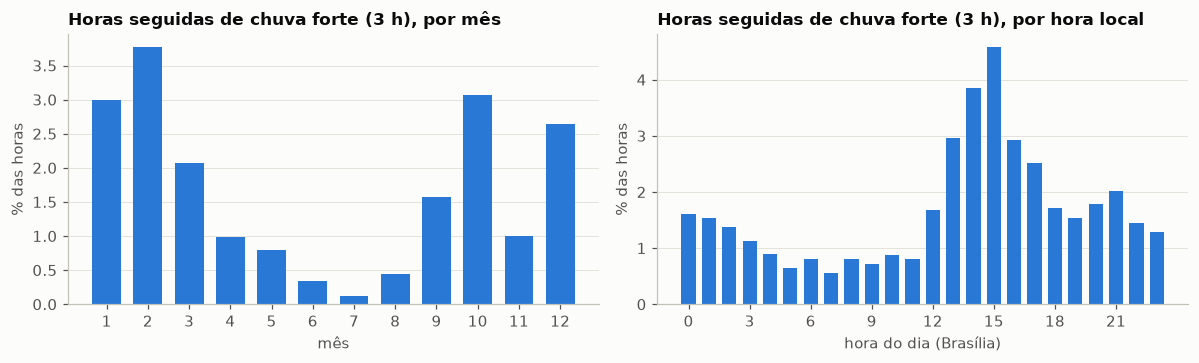

In [6]:
local = bases[3].index - pd.Timedelta(hours=3)
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.4))
por_mes = bases[3]['alvo'].groupby(local.month).mean() * 100
eixos[0].bar(por_mes.index, por_mes.values, color=COR_TREINO, width=0.7)
eixos[0].set_xticks(range(1, 13))
eixos[0].set_title('Horas seguidas de chuva forte (3 h), por mês')
eixos[0].set_xlabel('mês'); eixos[0].set_ylabel('% das horas')
por_hora = bases[3]['alvo'].groupby(local.hour).mean() * 100
eixos[1].bar(por_hora.index, por_hora.values, color=COR_TREINO, width=0.7)
eixos[1].set_xticks(range(0, 24, 3))
eixos[1].set_title('Horas seguidas de chuva forte (3 h), por hora local')
eixos[1].set_xlabel('hora do dia (Brasília)'); eixos[1].set_ylabel('% das horas')
for eixo in eixos:
    eixo.grid(axis='x', visible=False)
salvar('01_quando_chove_forte')

## 3. Divisão em treino e teste

O modelo aprende com o conjunto de treino e é avaliado no conjunto de teste, que não participa de nenhuma etapa de ajuste. Como os dados formam uma série temporal, as linhas não são embaralhadas: o teste corresponde a um período posterior ao do treino, como acontece no uso real.

- **Treino:** 2023, 2024 e 2025, três anos completos com todas as estações do ano.
- **Teste:** janeiro a outubro de 2026.

Dois cuidados evitam vazamento de informação do teste para o treino:
- as últimas horas de 2025 saem do treino, porque o alvo delas depende da chuva de 2026;
- a padronização dos atributos (média 0 e desvio padrão 1) é calculada somente com o treino e depois aplicada ao teste.

In [7]:
CORTE = pd.Timestamp('2026-01-01 00:00')


def dividir(base, horas):
    treino = base[base.index < CORTE - pd.Timedelta(hours=horas)]
    teste = base[base.index >= CORTE]
    return treino, teste


linhas = []
for horas, base in bases.items():
    treino, teste = dividir(base, horas)
    for nome, parte in (('treino', treino), ('teste', teste)):
        linhas.append({'horizonte': f'{horas} h', 'conjunto': nome,
                       'de': parte.index.min(), 'até': parte.index.max(), 'horas': len(parte),
                       'chuva forte (horas)': int(parte['alvo'].sum()),
                       '% positivas': round(parte['alvo'].mean() * 100, 2)})
pd.DataFrame(linhas)

,horizonte,conjunto,de,até,horas,chuva forte (horas),% positivas
0,3 h,treino,2023-01-01 23:00:00,2025-12-31 20:00:00,23370,400,1.71
1,3 h,teste,2026-01-01 00:00:00,2026-10-31 20:00:00,6388,97,1.52
2,6 h,treino,2023-01-01 23:00:00,2025-12-31 17:00:00,23143,854,3.69
3,6 h,teste,2026-01-01 00:00:00,2026-10-31 17:00:00,6322,232,3.67


## 4. Escolha do modelo

**Modelo principal: rede neural MLP (perceptron multicamadas) em PyTorch**, com uma camada escondida e ativação sigmoide, a mesma arquitetura vista em aula. O MLP foi escolhido por três motivos:

- a relação entre os atributos e a chuva forte não é linear: a umidade alta pesa mais quando a pressão está caindo, e a camada escondida permite combinar atributos dessa forma;
- a saída da rede é um logit, que a função sigmoide transforma em uma probabilidade entre 0 e 1, o formato recebido pela API;
- a rede é pequena, com algumas centenas de pesos, e treina em segundos em CPU.

**Modelos de comparação:**
- **Random Forest**, referência comum para dados em tabela, usada para verificar se a rede alcança o nível de um bom modelo;
- **regra simples**: emitir alerta quando já choveu nas últimas 3 horas, usada como nível mínimo a ser superado.

**Classe rara.** Menos de 4% das horas têm chuva forte. Um modelo que respondesse sempre "não" teria 96% de acurácia e nenhuma utilidade. Por isso:
1. a função de perda `BCEWithLogitsLoss` recebe `pos_weight` igual ao número de horas sem chuva forte dividido pelo número de horas com chuva forte, de modo que os erros na classe rara pesam mais;
2. a acurácia não é usada; as métricas são recall, precisão, F1 e PR-AUC, que avaliam a classe rara;
3. o limiar de decisão não é fixo em 0,5: ele é escolhido nos dados de validação.

Métricas usadas:
- **recall:** fração das chuvas fortes que o modelo avisou;
- **precisão:** fração dos alertas que foram seguidos de chuva forte;
- **F1:** média harmônica entre recall e precisão;
- **PR-AUC:** área sob a curva de precisão × recall, que resume o desempenho em todos os limiares, de 0 a 1.

In [8]:
class RedeChuva(nn.Module):
    def __init__(self, n_atributos, n_neuronios):
        super().__init__()
        self.layer1 = nn.Linear(n_atributos, n_neuronios)
        self.activation = torch.sigmoid
        self.layer2 = nn.Linear(n_neuronios, 1)

    def forward(self, x):
        x = self.layer1(x)
        x = self.activation(x)
        x = self.layer2(x)
        return x  # logit: a sigmoide é aplicada na perda e na hora de prever


def para_tensor(matriz):
    return torch.tensor(np.asarray(matriz), dtype=torch.float32).to(device)


EPOCAS = 400


def treinar_rede(X_train, y_train, n_neuronios, lr, weight_decay, X_val=None, y_val=None):
    """Treina a rede com o lote inteiro a cada época. Devolve o modelo e as curvas de erro."""
    torch.manual_seed(SEMENTE)
    X_train, y_train = para_tensor(X_train), para_tensor(y_train).view(-1, 1)
    if X_val is not None:
        X_val, y_val = para_tensor(X_val), para_tensor(y_val).view(-1, 1)

    model = RedeChuva(X_train.shape[1], n_neuronios).to(device)
    peso_positivo = (y_train == 0).sum() / (y_train == 1).sum()
    criterion = nn.BCEWithLogitsLoss(pos_weight=peso_positivo)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    erro, erro_val = [], []
    for i in range(EPOCAS):
        optimizer.zero_grad()
        preds = model.forward(X_train)
        loss = criterion(preds, y_train)
        loss.backward()
        optimizer.step()
        erro.append(loss.item())
        if X_val is not None:
            with torch.no_grad():
                erro_val.append(criterion(model.forward(X_val), y_val).item())
    return model, erro, erro_val


def prever(model, X):
    """Probabilidade (0 a 1) de chuva forte para cada linha."""
    with torch.no_grad():
        return torch.sigmoid(model.forward(para_tensor(X))).cpu().numpy().ravel()

## 5. Treino com diferentes hiperparâmetros

Três hiperparâmetros são variados, formando 12 combinações (3 × 2 × 2):

| Hiperparâmetro | Valores | Função |
|---|---|---|
| Neurônios na camada escondida | 4, 8, 16 | capacidade de aprendizado da rede |
| Taxa de aprendizado (`lr`) | 0,01 e 0,003 | tamanho de cada ajuste dos pesos no otimizador Adam |
| `weight_decay` | 0 e 0,001 | regularização que limita o tamanho dos pesos e reduz o overfitting |

Cada combinação é avaliada com validação cruzada temporal (`TimeSeriesSplit`, 3 dobras), feita somente dentro do treino. Em cada dobra, a rede treina com um trecho inicial e é avaliada no trecho seguinte, respeitando a ordem do tempo. Um intervalo de 24 h separa treino e validação, porque alguns atributos usam até 24 h de histórico. O teste de 2026 não participa dessa etapa.

A combinação escolhida é a de maior PR-AUC média na validação. O limiar de alerta é definido pelo F2, variação do F1 que dá ao recall o dobro do peso da precisão, porque deixar de avisar uma chuva forte tem custo maior que um alarme falso.

In [9]:
GRADE = list(itertools.product([4, 8, 16], [0.01, 0.003], [0.0, 0.001]))
DOBRAS = TimeSeriesSplit(n_splits=3, gap=24)


def validar_rede(X, y, n_neuronios, lr, weight_decay):
    """PR-AUC de treino e validação em cada dobra, mais as previsões de validação."""
    pr_treino, pr_val = [], []
    fora_da_amostra = np.full(len(y), np.nan)
    for idx_tr, idx_val in DOBRAS.split(X):
        escalador = StandardScaler().fit(X[idx_tr])
        X_tr, X_val = escalador.transform(X[idx_tr]), escalador.transform(X[idx_val])
        model, _, _ = treinar_rede(X_tr, y[idx_tr], n_neuronios, lr, weight_decay)
        fora_da_amostra[idx_val] = prever(model, X_val)
        pr_treino.append(average_precision_score(y[idx_tr], prever(model, X_tr)))
        pr_val.append(average_precision_score(y[idx_val], fora_da_amostra[idx_val]))
    return np.mean(pr_treino), np.mean(pr_val), fora_da_amostra


def buscar_hiperparametros(X, y):
    linhas, previsoes = [], {}
    for n_neuronios, lr, weight_decay in GRADE:
        pr_treino, pr_val, fora = validar_rede(X, y, n_neuronios, lr, weight_decay)
        linhas.append({'neuronios': n_neuronios, 'lr': lr, 'weight_decay': weight_decay,
                       'pr_auc_treino': pr_treino, 'pr_auc_validacao': pr_val})
        previsoes[(n_neuronios, lr, weight_decay)] = fora
    tabela = pd.DataFrame(linhas).sort_values('pr_auc_validacao', ascending=False)
    return tabela.reset_index(drop=True), previsoes


def escolher_limiar(y, probabilidade):
    """Limiar que maximiza o F2 (recall pesa o dobro da precisão) na validação.

    Perder uma chuva forte custa mais caro que um alarme falso, por isso o F2 e não o F1.
    """
    validas = ~np.isnan(probabilidade)
    precisao, recall, limiares = precision_recall_curve(y[validas], probabilidade[validas])
    f2 = 5 * precisao * recall / np.maximum(4 * precisao + recall, 1e-12)
    return float(limiares[np.argmax(f2[:-1])])


def medir(y, probabilidade, limiar):
    alerta = probabilidade >= limiar
    return {'recall': recall_score(y, alerta), 'precisao': precision_score(y, alerta, zero_division=0),
            'f1': f1_score(y, alerta), 'pr_auc': average_precision_score(y, probabilidade)}

A função abaixo executa o experimento completo de um horizonte: busca de hiperparâmetros, treino do modelo final e comparação com a Random Forest. O mesmo procedimento é aplicado aos horizontes de 3 h e 6 h.

In [10]:
def executar_experimento(horas):
    treino, teste = dividir(bases[horas], horas)
    X_treino, y_treino = treino[ATRIBUTOS].values, treino['alvo'].values
    X_teste, y_teste = teste[ATRIBUTOS].values, teste['alvo'].values

    # 1) busca de hiperparâmetros com validação cruzada temporal, só no treino
    grade, previsoes_val = buscar_hiperparametros(X_treino, y_treino)
    melhor = grade.iloc[0]
    config = (int(melhor['neuronios']), float(melhor['lr']), float(melhor['weight_decay']))
    limiar = escolher_limiar(y_treino, previsoes_val[config])

    # 2) modelo final: melhor combinação, treinada no treino inteiro
    escalador = StandardScaler().fit(X_treino)
    Xn_treino, Xn_teste = escalador.transform(X_treino), escalador.transform(X_teste)
    model, erro, erro_teste = treinar_rede(Xn_treino, y_treino, *config, X_val=Xn_teste, y_val=y_teste)
    p_treino, p_teste = prever(model, Xn_treino), prever(model, Xn_teste)

    # 3) Random Forest de comparação, avaliada do mesmo jeito
    def nova_floresta():
        return RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=20,
                                      class_weight='balanced_subsample', n_jobs=-1, random_state=SEMENTE)
    fora_rf = np.full(len(y_treino), np.nan)
    pr_val_rf = []
    for idx_tr, idx_val in DOBRAS.split(X_treino):
        floresta = nova_floresta().fit(X_treino[idx_tr], y_treino[idx_tr])
        fora_rf[idx_val] = floresta.predict_proba(X_treino[idx_val])[:, 1]
        pr_val_rf.append(average_precision_score(y_treino[idx_val], fora_rf[idx_val]))
    limiar_rf = escolher_limiar(y_treino, fora_rf)
    floresta = nova_floresta().fit(X_treino, y_treino)
    p_treino_rf = floresta.predict_proba(X_treino)[:, 1]
    p_teste_rf = floresta.predict_proba(X_teste)[:, 1]

    return {
        'horas': horas, 'treino': treino, 'teste': teste, 'grade': grade, 'config': config,
        'limiar': limiar, 'escalador': escalador, 'model': model, 'erro': erro, 'erro_teste': erro_teste,
        'y_treino': y_treino, 'y_teste': y_teste, 'p_treino': p_treino, 'p_teste': p_teste,
        'peso_positivo': float((y_treino == 0).sum() / (y_treino == 1).sum()),
        'metricas_treino': medir(y_treino, p_treino, limiar),
        'metricas_teste': medir(y_teste, p_teste, limiar),
        'floresta': floresta, 'limiar_rf': limiar_rf, 'pr_val_rf': float(np.mean(pr_val_rf)),
        'p_teste_rf': p_teste_rf,
        'metricas_treino_rf': medir(y_treino, p_treino_rf, limiar_rf),
        'metricas_teste_rf': medir(y_teste, p_teste_rf, limiar_rf),
        'pr_auc_regra': average_precision_score(y_teste, teste['chuva_3h'].values),
    }


resultados = {}
for horas in (3, 6):
    resultados[horas] = executar_experimento(horas)
    r = resultados[horas]
    print(f'Horizonte {horas} h -> melhor combinação: {r["config"][0]} neurônios, lr={r["config"][1]}, '
          f'weight_decay={r["config"][2]} | limiar escolhido na validação: {r["limiar"]:.3f}')

Horizonte 3 h -> melhor combinação: 16 neurônios, lr=0.003, weight_decay=0.001 | limiar escolhido na validação: 0.801


Horizonte 6 h -> melhor combinação: 16 neurônios, lr=0.01, weight_decay=0.001 | limiar escolhido na validação: 0.568


### Resultado das 12 combinações

Combinações ordenadas pela PR-AUC de validação, da maior para a menor.

In [11]:
for horas in (3, 6):
    print(f'Horizonte de {horas} h (ordenado pela PR-AUC de validação)')
    display(resultados[horas]['grade'].round(4))

Horizonte de 3 h (ordenado pela PR-AUC de validação)


,neuronios,lr,weight_decay,pr_auc_treino,pr_auc_validacao
0,16,0.003,0.001,0.1806,0.1631
1,8,0.003,0.001,0.1657,0.1624
2,8,0.003,0.000,0.1637,0.1605
3,16,0.003,0.000,0.1848,0.1586
4,16,0.010,0.001,0.3030,0.1573
5,4,0.010,0.001,0.1931,0.1571
6,8,0.010,0.001,0.2225,0.1560
7,4,0.010,0.000,0.1813,0.1489
8,16,0.010,0.000,0.3175,0.1450
9,8,0.010,0.000,0.2307,0.1398


Horizonte de 6 h (ordenado pela PR-AUC de validação)


,neuronios,lr,weight_decay,pr_auc_treino,pr_auc_validacao
0,16,0.010,0.001,0.4064,0.2042
1,16,0.003,0.001,0.2662,0.2030
2,8,0.010,0.000,0.3319,0.2017
3,16,0.003,0.000,0.2674,0.2010
4,8,0.010,0.001,0.3299,0.1982
5,8,0.003,0.001,0.2373,0.1974
6,4,0.010,0.001,0.2742,0.1942
7,8,0.003,0.000,0.2352,0.1933
8,16,0.010,0.000,0.4327,0.1864
9,4,0.010,0.000,0.2724,0.1849


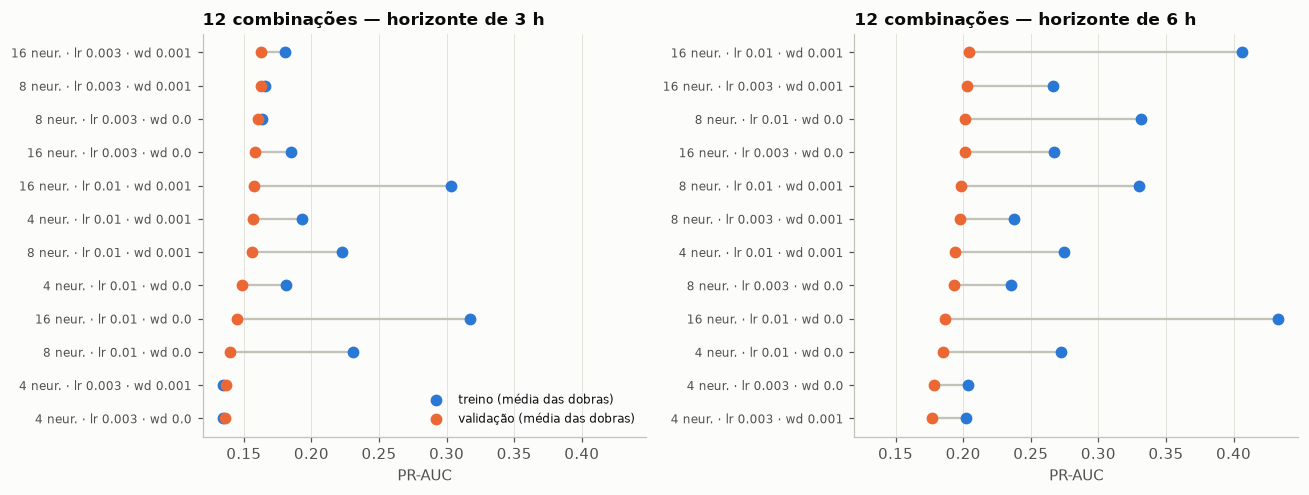

In [12]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True)
for eixo, horas in zip(eixos, (3, 6)):
    grade = resultados[horas]['grade'].iloc[::-1]
    rotulos = [f'{int(n)} neur. · lr {lr} · wd {wd}' for n, lr, wd in
               zip(grade['neuronios'], grade['lr'], grade['weight_decay'])]
    posicoes = np.arange(len(grade))
    eixo.hlines(posicoes, grade['pr_auc_validacao'], grade['pr_auc_treino'], color='#c3c2b7', linewidth=1.5)
    eixo.scatter(grade['pr_auc_treino'], posicoes, color=COR_TREINO, s=45, zorder=3, label='treino (média das dobras)')
    eixo.scatter(grade['pr_auc_validacao'], posicoes, color=COR_TESTE, s=45, zorder=3, label='validação (média das dobras)')
    eixo.set_yticks(posicoes); eixo.set_yticklabels(rotulos, fontsize=8)
    eixo.set_xlabel('PR-AUC'); eixo.set_title(f'12 combinações — horizonte de {horas} h')
    eixo.grid(axis='y', visible=False)
eixos[0].legend(loc='lower right', fontsize=8)
salvar('02_busca_hiperparametros')

**Resultado da busca:**

- As combinações têm desempenho próximo na validação: de 0,14 a 0,16 em 3 h e de 0,18 a 0,20 em 6 h. O tamanho da rede tem pouco efeito; o limite vem da informação disponível em uma única estação.
- **Subajuste:** com 4 neurônios e `lr` 0,003, treino e validação ficam iguais e baixos. A rede é pequena demais e não termina de aprender em 400 épocas.
- **Overfitting:** com 16 neurônios, `lr` 0,01 e sem `weight_decay`, a PR-AUC de treino é a mais alta (0,32 em 3 h e 0,43 em 6 h), mas a de validação fica entre as piores. A rede memoriza o treino.
- O `weight_decay` melhora a validação em 10 das 12 comparações.
- **Combinações escolhidas:** 16 neurônios, `lr` 0,003 e `weight_decay` 0,001 para 3 h; 16 neurônios, `lr` 0,01 e `weight_decay` 0,001 para 6 h. Em 6 h, as quatro primeiras colocadas ficam praticamente empatadas (diferença de 0,003).

## 6. Resultados em treino e teste

O modelo final de cada horizonte usa a combinação escolhida e é treinado com todo o treino (2023 a 2025). O teste (2026) é usado aqui pela primeira vez.

### Curva de erro

O erro (perda) é registrado a cada época, isto é, a cada passagem completa pelos dados de treino. Quando o erro do treino continua caindo e o do teste para de cair ou sobe, há overfitting. A curva do teste é apenas acompanhada e não é usada em nenhuma decisão.

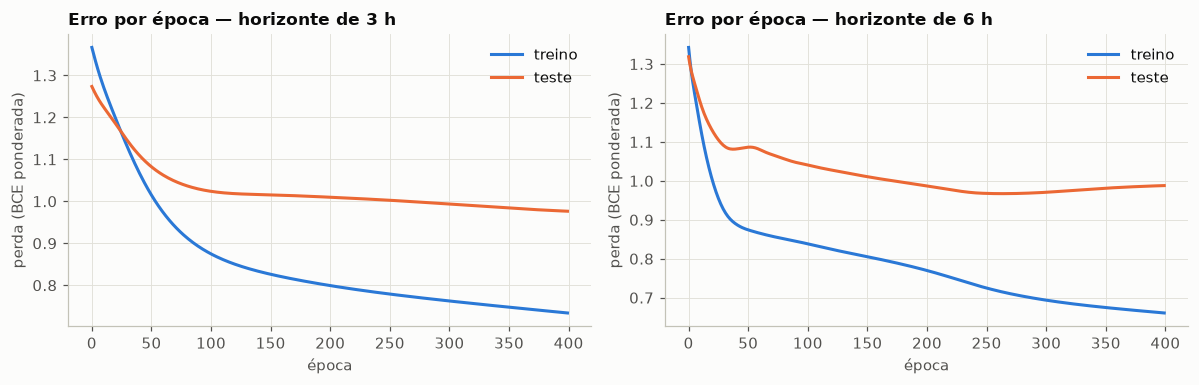

In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6))
for eixo, horas in zip(eixos, (3, 6)):
    r = resultados[horas]
    eixo.plot(r['erro'], color=COR_TREINO, label='treino')
    eixo.plot(r['erro_teste'], color=COR_TESTE, label='teste')
    eixo.set_title(f'Erro por época — horizonte de {horas} h')
    eixo.set_xlabel('época'); eixo.set_ylabel('perda (BCE ponderada)')
    eixo.legend()
salvar('03_curva_de_erro')

### Métricas lado a lado

Recall, precisão, F1 e PR-AUC no treino e no teste. Quanto menor a diferença entre os dois, menor o overfitting.

In [14]:
linhas = []
for horas in (3, 6):
    r = resultados[horas]
    for conjunto in ('treino', 'teste'):
        linhas.append({'horizonte': f'{horas} h', 'conjunto': conjunto, **r[f'metricas_{conjunto}']})
tabela_metricas = pd.DataFrame(linhas).set_index(['horizonte', 'conjunto']).round(3)
tabela_metricas

recall  precisao     f1  pr_auc
horizonte conjunto                                 
3 h       treino     0.542     0.153  0.239   0.162
          teste      0.340     0.071  0.118   0.087
6 h       treino     0.851     0.182  0.300   0.291
          teste      0.638     0.122  0.205   0.174

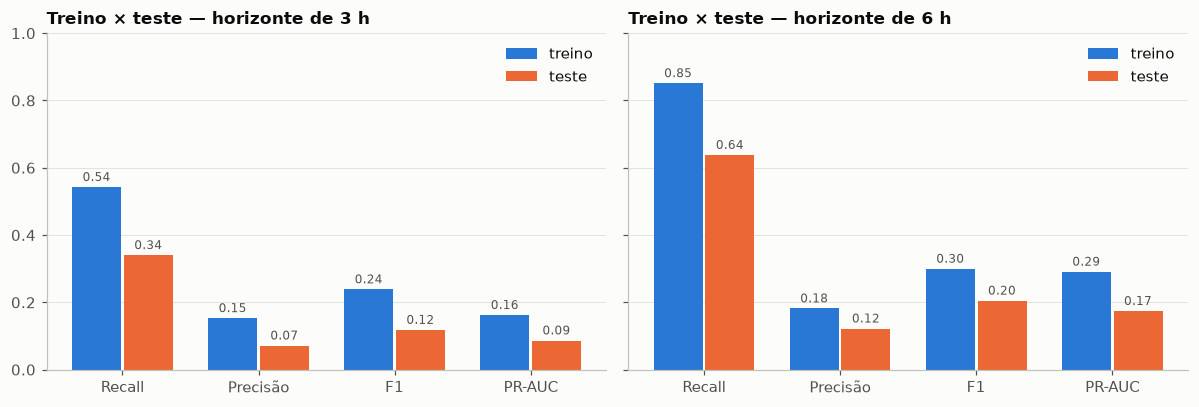

In [15]:
nomes = {'recall': 'Recall', 'precisao': 'Precisão', 'f1': 'F1', 'pr_auc': 'PR-AUC'}
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for eixo, horas in zip(eixos, (3, 6)):
    r = resultados[horas]
    posicoes = np.arange(len(nomes))
    for deslocamento, conjunto, cor in ((-0.19, 'treino', COR_TREINO), (0.19, 'teste', COR_TESTE)):
        valores = [r[f'metricas_{conjunto}'][m] for m in nomes]
        barras = eixo.bar(posicoes + deslocamento, valores, width=0.36, color=cor, label=conjunto)
        eixo.bar_label(barras, fmt='%.2f', fontsize=8, padding=2, color='#52514e')
    eixo.set_xticks(posicoes); eixo.set_xticklabels(nomes.values())
    eixo.set_ylim(0, 1); eixo.set_title(f'Treino × teste — horizonte de {horas} h')
    eixo.grid(axis='x', visible=False); eixo.legend()
salvar('04_metricas_treino_teste')

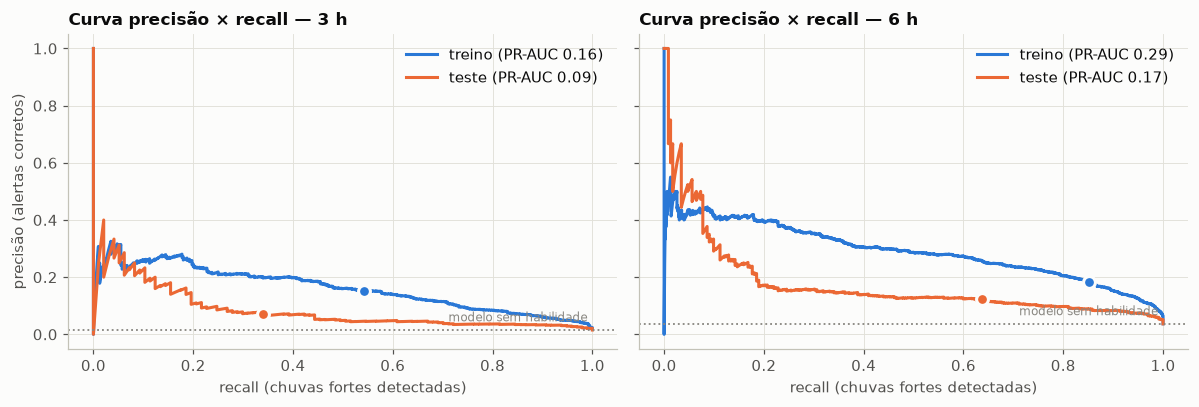

In [16]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for eixo, horas in zip(eixos, (3, 6)):
    r = resultados[horas]
    for conjunto, cor in (('treino', COR_TREINO), ('teste', COR_TESTE)):
        y, p = r[f'y_{conjunto}'], r[f'p_{conjunto}']
        precisao, recall, _ = precision_recall_curve(y, p)
        eixo.plot(recall, precisao, color=cor, label=f'{conjunto} (PR-AUC {average_precision_score(y, p):.2f})')
        m = r[f'metricas_{conjunto}']
        eixo.scatter([m['recall']], [m['precisao']], color=cor, s=60, zorder=3, edgecolor='#fcfcfb', linewidth=2)
    eixo.axhline(r['y_teste'].mean(), color=COR_NEUTRA, linestyle=':', linewidth=1.2)
    eixo.text(0.99, r['y_teste'].mean() + 0.03, 'modelo sem habilidade', ha='right', fontsize=8, color=COR_NEUTRA)
    eixo.set_xlabel('recall (chuvas fortes detectadas)'); eixo.set_title(f'Curva precisão × recall — {horas} h')
    eixo.legend()
eixos[0].set_ylabel('precisão (alertas corretos)')
salvar('05_curva_precisao_recall')

Em cada curva, o ponto marcado é o limiar escolhido na validação, e a linha pontilhada representa um modelo sem habilidade. Abaixo, a matriz de confusão do teste, com a quantidade de horas de acertos e erros em cada situação.

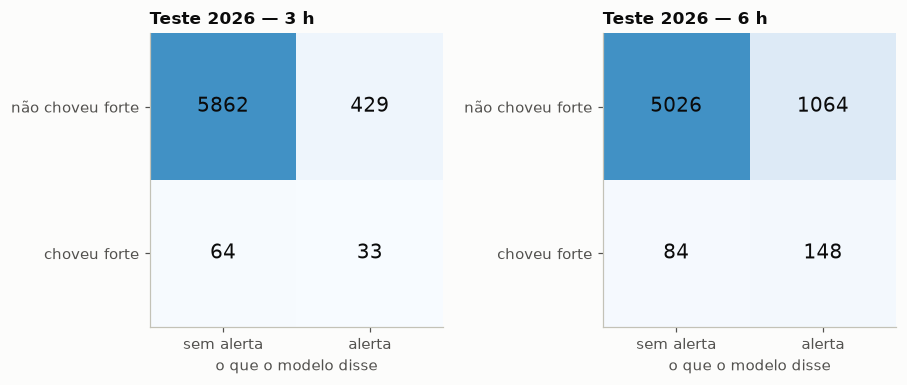

In [17]:
fig, eixos = plt.subplots(1, 2, figsize=(8.5, 3.6))
for eixo, horas in zip(eixos, (3, 6)):
    r = resultados[horas]
    matriz = confusion_matrix(r['y_teste'], r['p_teste'] >= r['limiar'])
    eixo.imshow(matriz, cmap='Blues', vmin=0, vmax=matriz.max() * 1.6)
    for i in range(2):
        for j in range(2):
            eixo.text(j, i, f'{matriz[i, j]}', ha='center', va='center', fontsize=13, color='#0b0b0b')
    eixo.set_xticks([0, 1]); eixo.set_xticklabels(['sem alerta', 'alerta'])
    eixo.set_yticks([0, 1]); eixo.set_yticklabels(['não choveu forte', 'choveu forte'])
    eixo.set_xlabel('o que o modelo disse'); eixo.set_title(f'Teste 2026 — {horas} h')
    eixo.grid(False)
salvar('06_matriz_confusao_teste')

**Overfitting: moderado, e não é a única causa da queda.**

- Todas as métricas caem do treino para o teste. A PR-AUC passa de 0,16 para 0,09 em 3 h e de 0,29 para 0,17 em 6 h; o recall passa de 0,54 para 0,34 em 3 h e de 0,85 para 0,64 em 6 h.
- A curva de erro de 6 h mostra o padrão típico: o erro do treino continua caindo, enquanto o do teste para de cair perto da época 250 e volta a subir levemente. Em 3 h, com `lr` menor, o erro do teste ainda cai devagar, mas a distância para o treino aumenta.
- Parte da queda não vem de overfitting. Em 3 h, o teste (0,09) fica abaixo até da validação cruzada (0,16), que também usa dados fora do treino. O teste de 3 h tem apenas 97 horas de chuva forte em dez meses, o que torna a medida instável, e 2026 pode ter tido tempestades mais difíceis de prever.
- O modelo tem habilidade real: a PR-AUC do teste é cerca de 6 vezes a de um modelo sem habilidade em 3 h (0,087 contra 0,015) e quase 5 vezes em 6 h (0,174 contra 0,037).

A precisão é baixa nos dois horizontes: 7% (3 h) e 12% (6 h) das horas com alerta são seguidas de chuva forte. Isso resulta da escolha do limiar pelo F2, que prioriza não perder chuvas fortes. A seção 8 traduz esse resultado em alarmes falsos por mês.

## 7. Comparação: 3 h × 6 h e rede × outros modelos

Métricas do teste para cada modelo. A linha "sem habilidade" corresponde à taxa de chuva forte no teste, o resultado de um modelo que não aprendeu nada.

In [18]:
linhas = []
for horas in (3, 6):
    r = resultados[horas]
    linhas.append({'horizonte': f'{horas} h', 'modelo': 'Rede neural MLP (PyTorch)', **r['metricas_teste'],
                   'pr_auc_treino': r['metricas_treino']['pr_auc']})
    linhas.append({'horizonte': f'{horas} h', 'modelo': 'Random Forest', **r['metricas_teste_rf'],
                   'pr_auc_treino': r['metricas_treino_rf']['pr_auc']})
    linhas.append({'horizonte': f'{horas} h', 'modelo': 'Regra: chuva das últimas 3 h', 'pr_auc': r['pr_auc_regra']})
    linhas.append({'horizonte': f'{horas} h', 'modelo': 'Sem habilidade (taxa de positivos)', 'pr_auc': r['y_teste'].mean()})
comparacao = pd.DataFrame(linhas).set_index(['horizonte', 'modelo']).round(3)
comparacao = comparacao.rename(columns={'pr_auc': 'pr_auc_teste', 'recall': 'recall_teste',
                                        'precisao': 'precisao_teste', 'f1': 'f1_teste'})
comparacao.astype(object).fillna('')

recall_teste precisao_teste  \
horizonte modelo                                                           
3 h       Rede neural MLP (PyTorch)                  0.34          0.071   
          Random Forest                             0.299          0.064   
          Regra: chuva das últimas 3 h                                     
          Sem habilidade (taxa de positivos)                               
6 h       Rede neural MLP (PyTorch)                 0.638          0.122   
          Random Forest                             0.591          0.126   
          Regra: chuva das últimas 3 h                                     
          Sem habilidade (taxa de positivos)                               

                                             f1_teste pr_auc_teste  \
horizonte modelo                                                     
3 h       Rede neural MLP (PyTorch)             0.118        0.087   
          Random Forest                         0.106        0.074   
          Regra: chuva das últimas 3 h                       0.072   
          Sem habilidade (taxa de positivos)                 0.015   
6 h       Rede neural MLP (PyTorch)             0.205        0.174   
          Random Forest                         0.207        0.154   
          Regra: chuva das últimas 3 h                       0.108   
          Sem habilidade (taxa de positivos)                 0.037   

                                             pr_auc_treino  
horizonte modelo                                            
3 h       Rede neural MLP (PyTorch)                  0.162  
          Random Forest                              0.586  
          Regra: chuva das últimas 3 h                      
          Sem habilidade (taxa de positivos)                
6 h       Rede neural MLP (PyTorch)                  0.291  
          Random Forest                              0.629  
          Regra: chuva das últimas 3 h                      
          Sem habilidade (taxa de positivos)

Importância dos atributos na Random Forest, que também indica quais variáveis mais explicam a chuva forte:

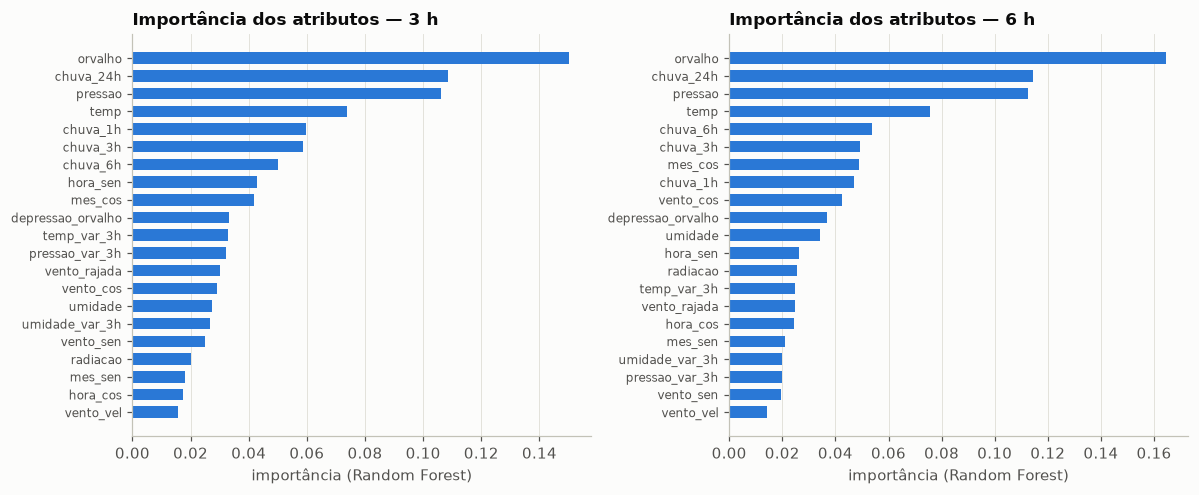

In [19]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.6))
for eixo, horas in zip(eixos, (3, 6)):
    importancia = pd.Series(resultados[horas]['floresta'].feature_importances_, index=ATRIBUTOS).sort_values()
    eixo.barh(importancia.index, importancia.values, color=COR_TREINO, height=0.65)
    eixo.set_title(f'Importância dos atributos — {horas} h'); eixo.set_xlabel('importância (Random Forest)')
    eixo.tick_params(axis='y', labelsize=8); eixo.grid(axis='y', visible=False)
salvar('07_importancia_atributos')

**3 h × 6 h.** O horizonte de 6 h é melhor em todas as métricas do teste: recall 0,64 contra 0,34, precisão 0,12 contra 0,07 e PR-AUC 0,17 contra 0,09. Há mais exemplos positivos para aprender (3,7% das horas contra 1,5%), e uma janela maior tolera o erro de horário, já que basta a tempestade cair em algum momento das seis horas. Em relação a um modelo sem habilidade, o ganho é parecido nos dois horizontes (cerca de 6 e 5 vezes).

**Rede × Random Forest.** Os dois modelos chegam praticamente ao mesmo resultado no teste. A rede fica um pouco à frente em PR-AUC (0,087 contra 0,074 em 3 h; 0,174 contra 0,154 em 6 h) e empata em F1 em 6 h. A Random Forest memoriza muito mais o treino (PR-AUC de treino perto de 0,6). Dois modelos diferentes no mesmo patamar indicam que o limite está nos dados.

**Regra simples.** Em 3 h, a rede supera por pouco a regra "já choveu nas últimas 3 h" (0,087 contra 0,072): nesse prazo, a maior parte do que se consegue prever é a continuação de uma chuva que já começou. Em 6 h, a rede acrescenta mais (0,174 contra 0,108).

**Atributos.** Ponto de orvalho, chuva das últimas 24 h, pressão e temperatura são os mais importantes. Ar quente e úmido em um período já chuvoso é o cenário das tempestades de verão em São Paulo.

## 8. O que isso significa para o cidadão

Recall e precisão são calculados em horas, mas para quem mora perto de um ponto de alagamento o que importa são os episódios de chuva. Por isso as horas são agrupadas:

- **Episódio de chuva forte:** sequência de horas consecutivas com alvo positivo. O episódio é considerado avisado se o modelo emitiu alerta em alguma dessas horas, ou seja, quando ainda faltavam pelo menos 10 mm para cair.
- **Antecedência:** tempo entre o primeiro alerta do episódio e a hora de chuva mais intensa.
- **Alarme falso:** sequência de alertas sem chuva forte em seguida.

In [20]:
def agrupar(momentos, folga_horas):
    """Agrupa horas próximas em episódios. Devolve lista de (início, fim)."""
    grupos = []
    for momento in momentos:
        if grupos and momento - grupos[-1][1] <= pd.Timedelta(hours=folga_horas):
            grupos[-1][1] = momento
        else:
            grupos.append([momento, momento])
    return grupos


def resumo_para_o_cidadao(r):
    horas, teste = r['horas'], r['teste']
    positivas = teste.index[r['y_teste'] == 1]
    alertas = teste.index[r['p_teste'] >= r['limiar']]

    episodios = agrupar(positivas, horas)
    avisados, antes_do_pico, antecedencias = 0, 0, []
    for inicio, fim in episodios:
        alertas_do_episodio = alertas[(alertas >= inicio) & (alertas <= fim)]
        if len(alertas_do_episodio) == 0:
            continue
        avisados += 1
        chuva_do_episodio = df['chuva'][inicio + pd.Timedelta(hours=1): fim + pd.Timedelta(hours=horas)]
        antecedencia = (chuva_do_episodio.idxmax() - alertas_do_episodio[0]) / pd.Timedelta(hours=1)
        if antecedencia > 0:
            antes_do_pico += 1
            antecedencias.append(antecedencia)

    sequencias_de_alerta = agrupar(alertas, horas)
    falsos = sum(1 for inicio, fim in sequencias_de_alerta
                 if not ((positivas >= inicio) & (positivas <= fim)).any())
    meses = (teste.index.max() - teste.index.min()) / pd.Timedelta(days=30.44)
    return {
        'horizonte': f'{horas} h',
        'episódios de chuva forte no teste': len(episodios),
        'episódios avisados': avisados,
        '% avisados': round(avisados / len(episodios) * 100, 1),
        'avisados antes do pico da chuva': antes_do_pico,
        'antecedência mediana até o pico (h)': float(np.median(antecedencias)) if antecedencias else np.nan,
        'sequências de alerta emitidas': len(sequencias_de_alerta),
        'alarmes falsos': falsos,
        'alarmes falsos por mês': round(falsos / meses, 1),
        'meses de teste': round(meses, 1),
    }


cidadao = pd.DataFrame([resumo_para_o_cidadao(resultados[h]) for h in (3, 6)]).set_index('horizonte').T
cidadao

horizonte,3 h,6 h
episódios de chuva forte no teste,31.0,39.0
episódios avisados,16.0,34.0
% avisados,51.6,87.2
avisados antes do pico da chuva,13.0,34.0
antecedência mediana até o pico (h),2.0,5.0
sequências de alerta emitidas,118.0,121.0
alarmes falsos,101.0,91.0
alarmes falsos por mês,10.1,9.1
meses de teste,10.0,10.0


### A probabilidade enviada à API

O `pos_weight` usado no treino faz a rede superestimar a probabilidade, como se a chuva forte fosse tão frequente quanto o tempo seco. Isso não afeta o alerta, porque o limiar foi escolhido na mesma escala, mas a probabilidade exibida ao cidadão precisa refletir a frequência real. A correção desfaz o efeito do peso: `p_real = p / (p + peso × (1 − p))`.

In [21]:
def corrigir_probabilidade(p, peso_positivo):
    return p / (p + peso_positivo * (1 - p))


for horas in (3, 6):
    r = resultados[horas]
    corrigida = corrigir_probabilidade(r['p_teste'], r['peso_positivo'])
    print(f'{horas} h -> probabilidade média prevista no teste: bruta {r["p_teste"].mean() * 100:.1f}%, '
          f'corrigida {corrigida.mean() * 100:.1f}% | frequência real de chuva forte: {r["y_teste"].mean() * 100:.1f}%')

3 h -> probabilidade média prevista no teste: bruta 28.8%, corrigida 1.8% | frequência real de chuva forte: 1.5%
6 h -> probabilidade média prevista no teste: bruta 28.0%, corrigida 4.2% | frequência real de chuva forte: 3.7%


**Resultado em termos de episódios (teste de janeiro a outubro de 2026):**

- **Alerta de 6 horas:** dos 39 episódios de chuva forte, 34 foram avisados (87%), todos antes da hora mais intensa, com 5 horas de antecedência na mediana. O custo é de cerca de 9 alarmes falsos por mês, pouco mais de dois por semana: de cada quatro alertas, um é seguido de chuva forte.
- **Alerta de 3 horas:** 16 de 31 episódios avisados (52%), com 2 horas de antecedência e 10 alarmes falsos por mês, resultado pior nos dois aspectos.

O alerta de 6 horas é o recomendado. Com um acerto para cada três alarmes falsos, ele não é adequado para orientar moradores a sair de casa, mas atende ao uso previsto no WaterLine: colocar a prefeitura em atenção e priorizar a limpeza das bocas de lobo que os sensores já indicam cheias. Um alarme falso custa uma vistoria preventiva; uma chuva forte não avisada custa um alagamento.

A probabilidade corrigida é coerente com a realidade na média (1,8% prevista contra 1,5% observada em 3 h; 4,2% contra 3,7% em 6 h) e é o valor enviado no campo `probabilidade` da API.

## 9. Visualização do que a rede aprendeu

A rede completa usa 21 atributos, o que não pode ser representado em um gráfico. Para visualizar o funcionamento, uma versão didática é treinada com apenas dois atributos (umidade e variação da pressão em 3 h) e 4 neurônios, e a superfície de decisão é desenhada como nos exemplos de aula. Essa versão serve apenas para visualização; os resultados anteriores são do modelo completo.

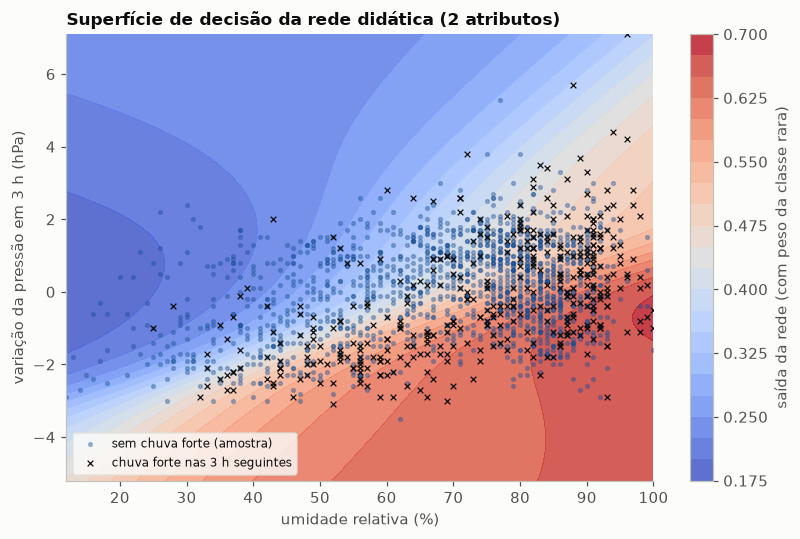

In [22]:
par = ['umidade', 'pressao_var_3h']
treino_3h, _ = dividir(bases[3], 3)
escalador_2d = StandardScaler().fit(treino_3h[par].values)
X_2d, y_2d = escalador_2d.transform(treino_3h[par].values), treino_3h['alvo'].values
model_2d, erro_2d, _ = treinar_rede(X_2d, y_2d, 4, 0.01, 0.0)

x0 = np.linspace(X_2d[:, 0].min(), X_2d[:, 0].max(), 200)
x1 = np.linspace(X_2d[:, 1].min(), X_2d[:, 1].max(), 200)
xx, yy = np.meshgrid(x0, x1)
malha = np.c_[xx.ravel(), yy.ravel()]
Z = prever(model_2d, malha).reshape(xx.shape)
# volta os eixos para as unidades originais (% e hPa)
original = escalador_2d.inverse_transform(malha)
ox, oy = original[:, 0].reshape(xx.shape), original[:, 1].reshape(xx.shape)

rng = np.random.default_rng(SEMENTE)
negativos = rng.choice(np.where(y_2d == 0)[0], 1500, replace=False)
positivos = np.where(y_2d == 1)[0]

plt.figure(figsize=(7.5, 5))
contorno = plt.contourf(ox, oy, Z, levels=20, cmap='coolwarm', alpha=0.85)
plt.colorbar(contorno, label='saída da rede (com peso da classe rara)')
plt.scatter(treino_3h[par[0]].values[negativos], treino_3h[par[1]].values[negativos],
            s=6, color='#184f95', alpha=0.35, label='sem chuva forte (amostra)')
plt.scatter(treino_3h[par[0]].values[positivos], treino_3h[par[1]].values[positivos],
            s=14, color='#0b0b0b', marker='x', linewidth=0.8, label='chuva forte nas 3 h seguintes')
plt.xlabel('umidade relativa (%)'); plt.ylabel('variação da pressão em 3 h (hPa)')
plt.title('Superfície de decisão da rede didática (2 atributos)')
plt.legend(loc='lower left', fontsize=8, frameon=True, facecolor='#fcfcfb', edgecolor='#e1e0d9')
plt.grid(False)
salvar('08_superficie_de_decisao')

Ativação de cada um dos 4 neurônios da camada escondida. Cada neurônio produz um corte suave no plano, e a saída da rede é a combinação desses cortes.

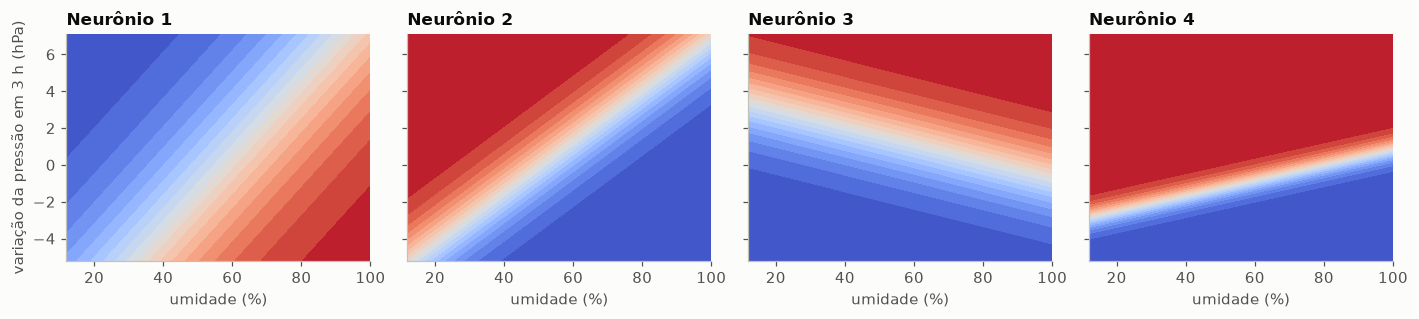

In [23]:
with torch.no_grad():
    ativacoes = model_2d.activation(model_2d.layer1(para_tensor(malha))).cpu().numpy()

fig, eixos = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for i, eixo in enumerate(eixos):
    eixo.contourf(ox, oy, ativacoes[:, i].reshape(xx.shape), levels=20, cmap='coolwarm')
    eixo.set_title(f'Neurônio {i + 1}'); eixo.set_xlabel('umidade (%)'); eixo.grid(False)
eixos[0].set_ylabel('variação da pressão em 3 h (hPa)')
salvar('09_ativacao_dos_neuronios')

A região vermelha, de maior risco, aparece com umidade alta e pressão em queda, o que é coerente com a meteorologia. A fronteira é curva por combinar os quatro neurônios, algo que um modelo linear não produziria. O gráfico também mostra a dificuldade do problema: os casos de chuva forte (×) estão misturados com as horas sem chuva. Com dois atributos eles não se separam, e mesmo com os 21 a separação é parcial.

## 10. Modelo salvo para a API

Para cada horizonte, a pasta `modelo/` recebe:
- os pesos da rede (`.pt`);
- o padronizador (`.joblib`), que aplica aos dados novos a mesma escala do treino;
- um arquivo de configuração (`.json`) com os atributos, o limiar de alerta e o peso da classe rara.

O script `enviar_previsao.py` lê esses arquivos, calcula a previsão para a hora mais recente dos dados e a envia ao endpoint `POST /previsoes` da API WaterLine.

In [24]:
for horas in (3, 6):
    r = resultados[horas]
    torch.save(r['model'].state_dict(), f'modelo/rede_chuva_{horas}h.pt')
    joblib.dump(r['escalador'], f'modelo/escalador_{horas}h.joblib')
    configuracao = {
        'horizonte_horas': horas, 'limite_mm': LIMITE_MM, 'atributos': ATRIBUTOS,
        'neuronios': r['config'][0], 'lr': r['config'][1], 'weight_decay': r['config'][2],
        'epocas': EPOCAS, 'limiar': r['limiar'], 'peso_positivo': r['peso_positivo'],
        'treino': [str(r['treino'].index.min()), str(r['treino'].index.max())],
        'teste': [str(r['teste'].index.min()), str(r['teste'].index.max())],
        'metricas_teste': {k: round(float(v), 4) for k, v in r['metricas_teste'].items()},
    }
    with open(f'modelo/config_{horas}h.json', 'w', encoding='utf-8') as arquivo:
        json.dump(configuracao, arquivo, ensure_ascii=False, indent=2)
print(sorted(os.listdir('modelo')))

['config_3h.json', 'config_6h.json', 'escalador_3h.joblib', 'escalador_6h.joblib', 'rede_chuva_3h.pt', 'rede_chuva_6h.pt']


In [25]:
# Exemplo do que será enviado: a última hora do conjunto de teste.
for horas in (3, 6):
    r = resultados[horas]
    ultima = r['teste'].index[-1]
    p_bruta = float(r['p_teste'][-1])
    print({'geradaEm': ultima.strftime('%Y-%m-%dT%H:%M:%SZ'), 'horizonteHoras': horas,
           'probabilidade': round(float(corrigir_probabilidade(p_bruta, r['peso_positivo'])), 4),
           'chuvaForte': bool(p_bruta >= r['limiar'])})

{'geradaEm': '2026-10-31T20:00:00Z', 'horizonteHoras': 3, 'probabilidade': 0.0216, 'chuvaForte': False}
{'geradaEm': '2026-10-31T17:00:00Z', 'horizonteHoras': 6, 'probabilidade': 0.0442, 'chuvaForte': False}


## Conclusão

- **Problema e dados:** previsão de chuva forte (10 mm ou mais) nas próximas 3 e 6 horas, com 33.600 horas de dados reais da estação INMET A701 (2023 a 2026).
- **Modelo:** rede neural MLP em PyTorch com uma camada escondida e perda ponderada para a classe rara, configurada a partir de 12 combinações de hiperparâmetros avaliadas por validação cruzada temporal.
- **Resultado no teste (2026):** com o alerta de 6 h, 87% dos episódios de chuva forte são avisados com 5 horas de antecedência, ao custo de 9 alarmes falsos por mês. Com o alerta de 3 h, metade dos episódios é avisada.
- **Limitações:** uma única estação não detecta tempestades que se formam a quilômetros de distância; a precisão é baixa (12%); há overfitting moderado; o teste cobre dez meses de um único ano.
- **Próximos passos:** incluir estações vizinhas e pluviômetros do CEMADEN, imagens de radar e previsão numérica do tempo, e avaliar com mais anos de teste. A transformação logarítmica da chuva e as variações de 1 hora dos sensores foram testadas na validação, não trouxeram ganho e ficaram fora do modelo.